## ANALISIS DE AGENTES ##

### Librerias

In [ ]:
import pandas as pd
import numpy as np
%pip install missingno
import missingno as msno
import matplotlib.pyplot as plt
import seaborn as sns

### Carga del dataset y formato de graficos

In [3]:
# Damos el formato a los graficos del matplotlib 
sns.set_theme(style = "whitegrid", palette = "viridis", font_scale = 1.1)

In [4]:
#Mostramos todas las columnas solicitadas en los graficos
pd.set_option('display.max_columns', None)

In [5]:
#Cargamos el dataset y realizamos un .shape para visualizar las dimensiones
df = pd.read_csv('Employee_Performance_Imputed_Distribution.csv', sep=",", decimal=".", encoding= "utf-8-sig")
df_original = df.copy() #Se genera una copia del original para mantener en caso de errores
print(df.shape)

(1200, 40)


### Nulos y duplicados

Nulos 0
Duplicados 0
EmpNumber unico: True


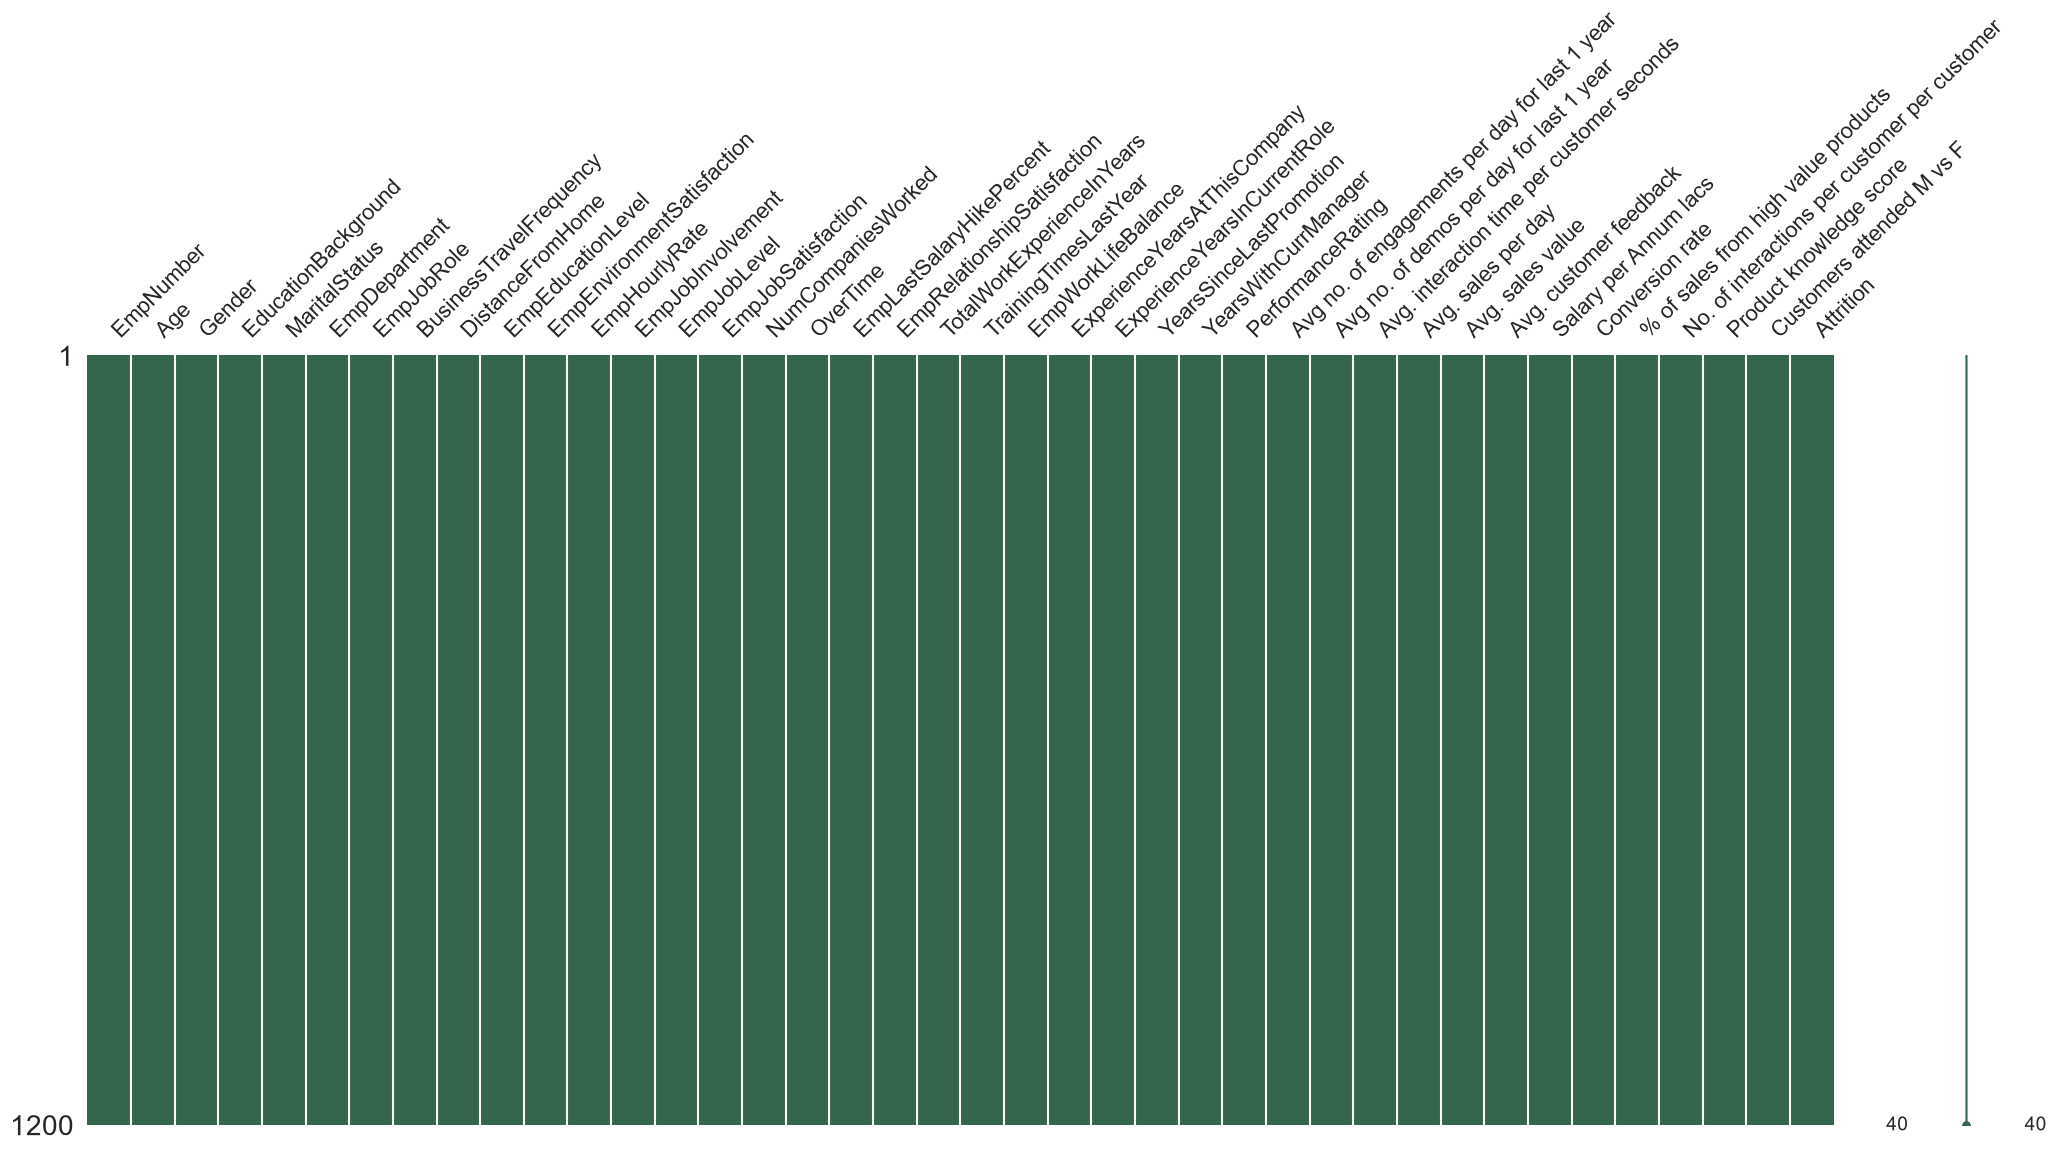

In [6]:
print("Nulos", df.isnull().sum().sum()) #Calculamos la cantidad de nulos
print("Duplicados", df.duplicated().sum()) #Calculamos la cantidad de duplicados
print("EmpNumber unico:", df["EmpNumber"].is_unique)# Medimos si EmpNumber es unico

msno.matrix(df, color=(0.2, 0.4, 0.3))
plt.show()

#No registra ni nulos ni duplicados

### Renombrar las columnas

In [7]:
renombres = {
    "EmpNumber": "emp_id", "Age": "edad", "Gender": "genero",
    "EducationBackground": "area_estudio", "MaritalStatus": "estado_civil",
    "EmpDepartment": "departamento", "EmpJobRole": "cargo",
    "BusinessTravelFrequency": "frecuencia_viaje",
    "DistanceFromHome": "distancia_casa", "EmpEducationLevel": "nivel_educativo",
    "EmpEnvironmentSatisfaction": "sat_ambiente", "EmpHourlyRate": "tarifa_hora",
    "EmpJobInvolvement": "involucramiento", "EmpJobLevel": "nivel_cargo",
    "EmpJobSatisfaction": "sat_trabajo", "NumCompaniesWorked": "n_empresas",
    "OverTime": "horas_extra", "EmpLastSalaryHikePercent": "aumento_salarial_pct",
    "EmpRelationshipSatisfaction": "sat_relaciones",
    "TotalWorkExperienceInYears": "exp_total_anios",
    "TrainingTimesLastYear": "capacitaciones_ult_anio",
    "EmpWorkLifeBalance": "balance_vida_trabajo",
    "ExperienceYearsAtThisCompany": "anios_empresa",
    "ExperienceYearsInCurrentRole": "anios_rol",
    "YearsSinceLastPromotion": "anios_desde_ascenso",
    "YearsWithCurrManager": "anios_con_gerente",
    "PerformanceRating": "calificacion_desempeno",
    "Avg no. of engagements per day for last 1 year": "contactos_dia",
    "Avg no. of demos per day for last 1 year": "demos_dia",
    "Avg. interaction time per customer seconds": "tiempo_interaccion_seg",
    "Avg. sales per day": "ventas_dia",
    "Avg. sales value": "valor_venta_prom",
    "Avg. customer feedback": "feedback_cliente",
    "Salary per Annum lacs": "salario_anual",        # supuesto: unidades monetarias
    "Conversion rate": "tasa_conversion",
    "% of sales from high value products": "pct_ventas_alto_valor",
    "No. of interactions per customer per customer": "interacciones_por_cliente",
    "Product knowledge score": "conocimiento_producto",
    "Customers attended M vs F": "prop_clientes_m_vs_f",
    "Attrition": "rotacion",
}
assert set(renombres) == set(df.columns), "Hay columnas sin renombrar" #El comando assert nos permite parar el codigo si hay un error y hay columnas sin renombrar
df = df.rename(columns=renombres)

In [8]:
#Verificamos que se renombraron las columnas
print(df)

        emp_id  edad  genero     area_estudio estado_civil     departamento  \
0     E1001000    32    Male        Marketing       Single            Sales   
1     E1001006    47    Male        Marketing       Single            Sales   
2     E1001007    40    Male    Life Sciences      Married            Sales   
3     E1001009    41    Male  Human Resources     Divorced  Human Resources   
4     E1001010    60    Male        Marketing       Single            Sales   
...        ...   ...     ...              ...          ...              ...   
1195   E100992    27  Female          Medical     Divorced            Sales   
1196   E100993    37    Male    Life Sciences       Single      Development   
1197   E100994    50    Male          Medical      Married      Development   
1198   E100995    34  Female          Medical       Single     Data Science   
1199   E100998    24  Female    Life Sciences       Single            Sales   

                 cargo   frecuencia_viaje  distanci

### Limpieza de texto

In [9]:
#El "+" nos permite unir listas, el "/" permite que el codigo siga a la sieguente linea
#En esta seccion se realiza una limpieza de texto que permite quitar espacios sobrantes al principio o al final de cada 
#texto u objeto, por ejempl;o "Male " se transforma en "Male" para que en su ranfgormacion no nos afecten con datos duplicados
cols_texto = df.select_dtypes(include="object").columns.tolist() + \
             df.select_dtypes(include="string").columns.tolist()
for c in set(cols_texto): #Busca cada linea con espacios sobrantes y los elimina, no afecta los que no tienen espacio
    df[c] = df[c].str.strip()

C:\Users\derek\AppData\Local\Temp\ipykernel_13084\4191430396.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols_texto = df.select_dtypes(include="object").columns.tolist() + \


### Binarias 

In [10]:
#Transformamos 3 columnas de texto en binarias, por ejempplo "Male"/"Female" las tranformamos en 0 o 1
#La variable se llama "genero_m" para identificar que male es 1 y female 0
df["genero_m"] = (df["genero"] == "Male").astype(int) # En esta linea preguntamos si en la variable genero esta "Male", lo convierta en TRUE y despues en .astype transforma ese TRUE en 1
df["horas_extra_bin"] = (df["horas_extra"] == "Yes").astype(int) # Lo mismo que genero
df["rotacion_bin"] = (df["rotacion"] == "Yes").astype(int) #Lo mismo que genero

### Frecuencia de Viaje

In [11]:
#Remplazamos los valores de frecuencia de viaje en 0,1,2 para futuras mediciones
#Todos lo guardamos en la variable "viaje_ord"
df["viaje_ord"] = df["frecuencia_viaje"].map( #El map busca cada palabra y lo transforma a numero, funciona como un diccionario de traduccion 
    {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}) #Definimos el valor de cada frecuencia

### Categorias sin orden

In [12]:
#Columnas de texto sin ordern las transformamos en 0 y 1 
#Se crean 6 columnas de estudio y 3 de estado civil
dummies = pd.get_dummies(df[["area_estudio", "estado_civil"]], #Seleccionamos las dos variables a convertir #get_dummies crea una columna por cada nuevo valor
                         prefix=["estudio", "civil"], dtype=int) #Colocamos un prefijo para reconocerlos #dtype nos permite que paarezcan como 1 y 0 y no como TRUE o False
df = pd.concat([df, dummies], axis=1) #Juntamos las dos tablas, axis le indica que se agreguen 1 despues de la otra
#No se eliminan las originales para el dashboard

### Revision de coherencia logica

In [13]:
#Nos permite verificar si hay datos con poca coherencia entre el tiempo laboral y jefes de cada empleado de esa manera buscar como tratar esos datos poco coherentes
#Si nos da mas de 0 el resultado quiere decir que hay un dato con poca coherencia en el dataset
print("\n--- Coherencia ---")
print("Años en empresa > exp. total:", (df["anios_empresa"] > df["exp_total_anios"]).sum())
print("Años en rol > años en empresa:", (df["anios_rol"] > df["anios_empresa"]).sum())
print("Años con gerente > años en empresa:", (df["anios_con_gerente"] > df["anios_empresa"]).sum())
print("Exp. total > edad - 14:", (df["exp_total_anios"] > df["edad"] - 14).sum())

#filas_raras = df[df["anios_empresa"] > df["exp_total_anios"]]
#print(filas_raras[["emp_id", "anios_empresa", "exp_total_anios"]])
### Estas ultimas 2 filas es en caso que haya un dato raro


--- Coherencia ---
Años en empresa > exp. total: 0
Años en rol > años en empresa: 0
Años con gerente > años en empresa: 0
Exp. total > edad - 14: 0


### Divison de vendedores


In [14]:
#Creamos una tabla que nos permita distinguir quienes son vendedores y quienes no
df["es_ventas"] = (df["departamento"] == "Sales").astype(int) #En esta seccion tranformamos la variable de ventas en donde el valor en departamento es de sales y con el astype lo convertimos a 1 y 0
df["es_agente_ventas"] = df["cargo"].isin(
    ["Sales Executive", "Sales Representative"]).astype(int) #Seleccionamos a los que trabajan en departamento sales executive y los de sales representative y los convertimos en 1 y 0
print("\nDepartamento Sales:", df["es_ventas"].sum()) #Imprimimos el total de ventas en los departamentos de ventas
print("Agentes:", df["es_agente_ventas"].sum()) #Imprimimos la cantidad de vendedores en los departamentos estudiados


Departamento Sales: 373
Agentes: 339


### Reporte de Outliers

In [15]:
#Vamos a realizar un reporte de Outliers sin afectar ninguna fila ni columna
metricas = ["contactos_dia", "demos_dia", "tiempo_interaccion_seg", "ventas_dia", #Definimos las metricas que son las columnas que vamos a revisar
            "valor_venta_prom", "feedback_cliente", "tasa_conversion",
            "pct_ventas_alto_valor", "conocimiento_producto", "salario_anual"]

def iqr_outliers(s): #Creamos una funcion para calcular los outliers
    q1, q3 = s.quantile([0.25, 0.75]) #Definimos el q1 y el q3
    i = q3 - q1  #Calculamos el IQR
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum() #Realizamos los calculos de la cantidad de outliers encima del q3 y debo del q1

ventas = df[df["es_ventas"] == 1] #Donde ventas es 1 osea es positivo lo que significa que si es una venta porque recordemos que se tranformo esta variable a binaria
print("\nOutliers en el equipo de ventas:") 
print(pd.Series({m: iqr_outliers(ventas[m]) for m in metricas})) #Esta linea recorre las metricas 1 por 1, el iqr_outliers aplica la funcion a cada columna y m: arma un diccionario, pd.series lo convierte en tabla de una columna


Outliers en el equipo de ventas:
contactos_dia              0
demos_dia                 12
tiempo_interaccion_seg     0
ventas_dia                 1
valor_venta_prom          23
feedback_cliente           1
tasa_conversion            4
pct_ventas_alto_valor      0
conocimiento_producto      4
salario_anual             13
dtype: int64


### Validacion y guardado

In [ ]:
#Guardamos el dataset final y validamos los cambios realizados
print("\nForma final:", df.shape) #Imprimimos las columnas y filas del dataset 
print("Nulos:", df.isnull().sum().sum()) #Imprimimos la cantidad de nulos 
print("Duplicados:", df.duplicated().sum()) #Impimimos la cantidad de duplicados

df.to_csv("empleados_limpio.csv", index=False) #Guardamos el dataset ya limipio
df[df["es_ventas"] == 1].to_csv("ventas_limpio.csv", index=False) #Guardamos un dataset unicamente con las ventas